# Infant SNe Rates

The goal of this notebook is to determine, for each of the five observing cadences, the number of infant SNe that UVEX would detect in the core mission. **Infant SNe** are the internal triggers we can expect to see with UVEX and use to trigger follow-up spectroscopy. We define an infant SN as follows:

- **Infant SN**: To ensure that spectroscopic follow-up is possible, we require that the event reach a brightness of **21 AB mag** or brighter (i.e. $m \le 21$, `INFANT_MAG`) in a $\ge 5\sigma$ detection within the first **48 hours** (`WINDOW_HR`) after the last non-detection in the same band.

To actually trigger on these events, we need cuts that can be applied early in the alert stream and serve as indicators. For a given event, we consider the following conditions, each evaluated on $\ge 5\sigma$ detections within 48 hours of the last non-detection in the same band:

(a) The event has brightened by at least $X$ AB magnitudes in at least 1 band, from the limit at its last non-detection to the current detection.

(b) The event is brightening at a rate of at least $Y$ AB mag / day in at least 1 band, from the limit at its last non-detection to the current detection.

(c) The event has an absolute magnitude brighter than $Z$ (i.e. $M \le Z$) in at least 1 band.

An event is **triggered** if and only if (a) OR (b) OR (c) is satisfied.

The thresholds $X$, $Y$ and $Z$, along with the infant magnitude and time window, are configurable in the Settings section below.


## Settings

In [101]:
# Imports. We work with the per-schedule event summary and photometry tables.
import warnings
from pathlib import Path
import numpy as np
from astropy.table import Table
from erfa import ErfaWarning

In [102]:
PRODUCTS_DIR = "../products"
SCHEDULES = ["6h", "1d", "2d", "4d", "10d"]


In [103]:
# Reading the time columns triggers "dubious year" warnings; they're harmless.
warnings.filterwarnings("ignore", category=ErfaWarning)

In [104]:
# ==================================== #
# Trigger configuration                #
# ==================================== #
DET_SNR = 5            # S/N for a detection (and for the limiting magnitude of a non-detection)
INFANT_MAG = 20.0      # infant SNe must reach m <= INFANT_MAG ...
WINDOW_HR = 48         # ... within this many hours of the last non-detection in the same band

X_BRIGHTEN = 3.0       # (a) brightening since the last non-detection limit, mag
Y_RATE = 3.0           # (b) brightening rate since the last non-detection limit, mag / day
Z_ABS_MAG = -15.0      # (c) absolute magnitude brighter than this (M <= Z)

USE_A, USE_B, USE_C = True, True, True   # which conditions enter the OR

In [105]:
# ==================================== #
# Load Tables into Memory              #
# ==================================== #
summary_tables = {}
photometry_tables = {}

for schedule in SCHEDULES:
    summary_path = Path(PRODUCTS_DIR) / f"infant_sne_{schedule}_event_summary.ecsv"
    photometry_path = Path(PRODUCTS_DIR) / f"infant_sne_{schedule}_photometry.ecsv"

    # Schedules with missing files are skipped.
    if not (summary_path.exists() and photometry_path.exists()):
        print(f"Skipping {schedule}: missing files")
        continue

    summary_tables[schedule] = Table.read(summary_path, format="ascii.ecsv")
    photometry_tables[schedule] = Table.read(photometry_path, format="ascii.ecsv")
    print(f"Loaded data for schedule {schedule}: {len(summary_tables[schedule])} events, {len(photometry_tables[schedule])} photometry rows")


Loaded data for schedule 6h: 579 events, 22108 photometry rows
Loaded data for schedule 1d: 704 events, 22922 photometry rows
Loaded data for schedule 2d: 800 events, 25574 photometry rows
Loaded data for schedule 4d: 807 events, 21934 photometry rows
Loaded data for schedule 10d: 764 events, 16070 photometry rows


## Table Manipulations

In [106]:
# =================================== #
# Add time since last non-det to phot #
# =================================== #

for schedule in SCHEDULES:
    if schedule not in photometry_tables:
        continue

    # extract the event table
    summary = summary_tables[schedule]
    photometry = photometry_tables[schedule]

    # Row of the summary table for each photometry row (event_id is unique in the summary).
    order = np.argsort(summary["event_id"])
    rows = order[np.searchsorted(summary["event_id"][order], photometry["event_id"])]

    # Last non-detection time (MJD) for the band of each photometry row; NaN where there is none.
    dt = np.full(len(photometry), np.nan)
    for band in ("FUV", "NUV"):
        t_nd = summary[f"t_last_nondet_{band}"]
        t_nd_mjd = np.ma.filled(t_nd.mjd, np.nan)[rows]
        in_band = photometry["band"] == band
        dt[in_band] = photometry["obs_time"].mjd[in_band] - t_nd_mjd[in_band]

    # Days since the last non-detection in the same band (negative if the exposure precedes it).
    photometry["dt_last_nondet"] = dt
    photometry["dt_last_nondet"].unit = "d"

    photometry_tables[schedule] = photometry


In [107]:
# =================================== #
# Add the abs mag                     #
# =================================== #
# For each epoch, compute the absolute magnitude by subtracting the distance modulus (from the
# luminosity distance in the summary table) from the apparent magnitude. This is the observed-band
# absolute magnitude (m - mu), so Z in condition (c) is defined in the observed band.
for schedule in SCHEDULES:
    if schedule not in photometry_tables:
        continue

    # extract the event table
    summary = summary_tables[schedule]
    photometry = photometry_tables[schedule]

    # Row of the summary table for each photometry row (event_id is unique in the summary).
    order = np.argsort(summary["event_id"])
    rows = order[np.searchsorted(summary["event_id"][order], photometry["event_id"])]

    # Distance modulus from the luminosity distance (Mpc).
    d_l_pc = np.asarray(summary["luminosity_distance"], dtype=float) * 1e6
    distance_modulus = 5 * np.log10(d_l_pc / 10)

    photometry["abs_mag"] = np.asarray(photometry["ab_mag"]) - distance_modulus[rows]
    photometry["abs_mag"].unit = "mag"

    photometry_tables[schedule] = photometry

In [108]:
# =================================== #
# Add the last non-det limit to phot  #
# =================================== #
# The brightening in (a) and (b) is measured from the 5-sigma limiting magnitude of the last
# non-detection (in the same band) to the current detection. That non-detection is one of the
# photometry rows, so look it up by (event, band, time). Where the non-detection predates the
# stored photometry, the limit is left as NaN, and (a)/(b) cannot be satisfied (such an epoch is
# also far outside the 48 hr window).
for schedule in SCHEDULES:
    if schedule not in photometry_tables:
        continue

    summary = summary_tables[schedule]
    photometry = photometry_tables[schedule]

    order = np.argsort(summary["event_id"])
    rows = order[np.searchsorted(summary["event_id"][order], photometry["event_id"])]

    # 5-sigma limiting AB magnitude of every exposure (flux in Jy).
    m_limit = -2.5 * np.log10(DET_SNR * np.asarray(photometry["flux_err"]) / 3631)
    obs_mjd = photometry["obs_time"].mjd

    m_last_nondet = np.full(len(photometry), np.nan)
    for band in ("FUV", "NUV"):
        t_nd_mjd = np.ma.filled(summary[f"t_last_nondet_{band}"].mjd, np.nan)
        in_band = np.asarray(photometry["band"]) == band

        # Photometry rows that are the last non-detection of their event in this band.
        is_nondet = in_band & (np.abs(obs_mjd - t_nd_mjd[rows]) < 1e-6)
        limit_by_event = np.full(len(summary), np.nan)
        limit_by_event[rows[is_nondet]] = m_limit[is_nondet]

        m_last_nondet[in_band] = limit_by_event[rows[in_band]]

    photometry["m_last_nondet"] = m_last_nondet
    photometry["m_last_nondet"].unit = "mag"

    photometry_tables[schedule] = photometry

## Cuts

In [109]:
# =================================== #
# Cut: infant SNe                     #
# =================================== #
# The first cut is to require that the event actually is an infant SN, i.e. that it reached the
# brightness threshold (INFANT_MAG) within WINDOW_HR of the last non-detection. Whether or not we
# would have triggered on it, such an SN is a candidate for follow-up spectroscopy.

infant_summary_tables = {}
infant_phot_tables = {}
infant_theory_event_ids = {}

for schedule in SCHEDULES:
    if schedule not in photometry_tables:
        continue

    summary = summary_tables[schedule]
    photometry = photometry_tables[schedule]

    # Infant: some epoch with SNR >= DET_SNR, ab_mag <= INFANT_MAG and dt_last_nondet <= WINDOW_HR.
    is_infant = (photometry["ab_mag"] <= INFANT_MAG) & \
                (photometry["dt_last_nondet"] <= WINDOW_HR / 24) & \
                (photometry["snr"] >= DET_SNR)

    # "Theory" infant: the same, but with the window anchored on the true explosion time (rel_time)
    # rather than the last non-detection, so it does not depend on the cadence.
    is_infant_theory = (photometry["ab_mag"] <= INFANT_MAG) & \
                (photometry["rel_time"] <= WINDOW_HR / 24) & \
                (photometry["snr"] >= DET_SNR)

    event_ids = np.asarray(list(set(photometry["event_id"][is_infant])))
    event_ids_theory = np.asarray(list(set(photometry["event_id"][is_infant_theory])))

    print(f"There are {len(event_ids)} infant SNe in {schedule}. There are {len(event_ids_theory)} theory SNe in {schedule}.")

    infant_summary_tables[schedule] = summary[np.isin(summary["event_id"], event_ids)]
    infant_phot_tables[schedule] = photometry[np.isin(photometry["event_id"], event_ids)]
    infant_theory_event_ids[schedule] = event_ids_theory


There are 11 infant SNe in 6h. There are 77 theory SNe in 6h.
There are 11 infant SNe in 1d. There are 70 theory SNe in 1d.
There are 5 infant SNe in 2d. There are 75 theory SNe in 2d.
There are 3 infant SNe in 4d. There are 95 theory SNe in 4d.
There are 3 infant SNe in 10d. There are 79 theory SNe in 10d.


In [110]:
# =================================== #
# Cut (a): Delta AB Mag >= X          #
# =================================== #
# For each infant SN, find the earliest epoch at which condition (a) holds, i.e. a >= DET_SNR
# detection within WINDOW_HR of the last non-detection in the same band that has brightened by
# at least X_BRIGHTEN mag relative to the 5-sigma limit of that non-detection.
#
#   cut_a_event_ids[schedule]    : event_id of each infant SN that passes (a)
#   cut_a_phot_indices[schedule] : row of infant_phot_tables[schedule] holding its earliest
#                                  passing epoch (same order as the event ids)

def earliest_passing_rows(photometry, epoch_mask):
    """Event ids and photometry rows of the earliest epoch of each event for which epoch_mask holds.

    Both bands are exposed together, so ties between bands resolve to whichever row comes first
    in the table.
    """
    candidates = np.flatnonzero(epoch_mask)
    event_id = np.asarray(photometry["event_id"])[candidates]
    by_event_time = np.lexsort((photometry["obs_time"].mjd[candidates], event_id))
    candidates = candidates[by_event_time]
    event_ids, first = np.unique(event_id[by_event_time], return_index=True)
    return event_ids, candidates[first]


cut_a_event_ids = {}
cut_a_phot_indices = {}

for schedule in SCHEDULES:
    if schedule not in infant_phot_tables:
        continue

    summary = infant_summary_tables[schedule]
    photometry = infant_phot_tables[schedule]

    # Brightening (mag, > 0 when brighter) from the last non-detection limit to this detection.
    # The limit is NaN where the non-detection is not in the photometry, so those epochs never pass.
    dt = np.asarray(photometry["dt_last_nondet"])
    with np.errstate(invalid="ignore"):
        brightening = np.asarray(photometry["m_last_nondet"]) - np.asarray(photometry["ab_mag"])
        meets_a = (
            (np.asarray(photometry["snr"]) >= DET_SNR)
            & (dt > 0) & (dt <= WINDOW_HR / 24)
            & (brightening >= X_BRIGHTEN)
        )

    event_ids, rows = earliest_passing_rows(photometry, meets_a)
    cut_a_event_ids[schedule] = event_ids
    cut_a_phot_indices[schedule] = rows

    print(f"{schedule}: {len(event_ids)} of {len(summary)} infant SNe pass (a) (brightened >= {X_BRIGHTEN} mag)")


6h: 11 of 11 infant SNe pass (a) (brightened >= 3.0 mag)
1d: 11 of 11 infant SNe pass (a) (brightened >= 3.0 mag)
2d: 5 of 5 infant SNe pass (a) (brightened >= 3.0 mag)
4d: 3 of 3 infant SNe pass (a) (brightened >= 3.0 mag)
10d: 3 of 3 infant SNe pass (a) (brightened >= 3.0 mag)


In [111]:
# =================================== #
# Cut (b): Delta AB Mag / day >= Y    #
# =================================== #
# For each infant SN, find the earliest epoch at which condition (b) holds, i.e. a >= DET_SNR
# detection within WINDOW_HR of the last non-detection in the same band that has brightened at a
# rate of at least Y_RATE mag / day since the 5-sigma limit of that non-detection.
#
#   cut_b_event_ids[schedule]    : event_id of each infant SN that passes (b)
#   cut_b_phot_indices[schedule] : row of infant_phot_tables[schedule] holding its earliest
#                                  passing epoch (same order as the event ids)

cut_b_event_ids = {}
cut_b_phot_indices = {}

for schedule in SCHEDULES:
    if schedule not in infant_phot_tables:
        continue

    summary = infant_summary_tables[schedule]
    photometry = infant_phot_tables[schedule]

    # Rate (mag / day, > 0 when brightening) from the last non-detection limit to this detection.
    dt = np.asarray(photometry["dt_last_nondet"])
    with np.errstate(invalid="ignore", divide="ignore"):
        brightening = np.asarray(photometry["m_last_nondet"]) - np.asarray(photometry["ab_mag"])
        rate = brightening / dt
        meets_b = (
            (np.asarray(photometry["snr"]) >= DET_SNR)
            & (dt > 0) & (dt <= WINDOW_HR / 24)
            & (rate >= Y_RATE)
        )

    event_ids, rows = earliest_passing_rows(photometry, meets_b)
    cut_b_event_ids[schedule] = event_ids
    cut_b_phot_indices[schedule] = rows

    print(f"{schedule}: {len(event_ids)} of {len(summary)} infant SNe pass (b) (rate >= {Y_RATE} mag/day)")


6h: 9 of 11 infant SNe pass (b) (rate >= 3.0 mag/day)
1d: 10 of 11 infant SNe pass (b) (rate >= 3.0 mag/day)
2d: 3 of 5 infant SNe pass (b) (rate >= 3.0 mag/day)
4d: 3 of 3 infant SNe pass (b) (rate >= 3.0 mag/day)
10d: 3 of 3 infant SNe pass (b) (rate >= 3.0 mag/day)


In [112]:
# =================================== #
# Cut (c): ABS MAG <= Z               #
# =================================== #
# For each infant SN, find the earliest epoch at which condition (c) holds, i.e. a >= DET_SNR
# detection within WINDOW_HR of the last non-detection in the same band that is brighter than
# Z_ABS_MAG. That epoch is the time at which the (c) trigger would fire.
#
#   cut_c_event_ids[schedule]    : event_id of each infant SN that passes (c)
#   cut_c_phot_indices[schedule] : row of infant_phot_tables[schedule] holding its earliest
#                                  passing epoch (same order as the event ids)

cut_c_event_ids = {}
cut_c_phot_indices = {}

for schedule in SCHEDULES:
    if schedule not in infant_phot_tables:
        continue

    summary = infant_summary_tables[schedule]
    photometry = infant_phot_tables[schedule]

    # Look at the photometry and find any cases where we have exceeded
    # the abs mag threshold. The earliest of these is the time we want to record.
    dt = np.asarray(photometry["dt_last_nondet"])
    meets_c = (
        (np.asarray(photometry["snr"]) >= DET_SNR)
        & (dt > 0) & (dt <= WINDOW_HR / 24)
        & (np.asarray(photometry["abs_mag"]) <= Z_ABS_MAG)
    )

    event_ids, rows = earliest_passing_rows(photometry, meets_c)
    cut_c_event_ids[schedule] = event_ids
    cut_c_phot_indices[schedule] = rows

    print(f"{schedule}: {len(event_ids)} of {len(summary)} infant SNe pass (c) (M <= {Z_ABS_MAG})")


6h: 11 of 11 infant SNe pass (c) (M <= -15.0)
1d: 11 of 11 infant SNe pass (c) (M <= -15.0)
2d: 5 of 5 infant SNe pass (c) (M <= -15.0)
4d: 3 of 3 infant SNe pass (c) (M <= -15.0)
10d: 3 of 3 infant SNe pass (c) (M <= -15.0)


In [113]:
# =================================== #
# Union of the cuts                   #
# =================================== #
# An infant SN is caught if (a) OR (b) OR (c) holds (restricted to the conditions switched on
# by USE_A / USE_B / USE_C).
#
#   triggered_event_ids[schedule] : event_id of each infant SN caught by the union

cuts = {
    "a": (USE_A, cut_a_event_ids),
    "b": (USE_B, cut_b_event_ids),
    "c": (USE_C, cut_c_event_ids),
}

triggered_event_ids = {}

for schedule in SCHEDULES:
    if schedule not in infant_summary_tables:
        continue

    infant_ids = np.asarray(infant_summary_tables[schedule]["event_id"])
    passing = [ids[schedule] for use, ids in cuts.values() if use]
    caught = np.unique(np.concatenate(passing)) if passing else np.array([], dtype=infant_ids.dtype)
    triggered_event_ids[schedule] = caught

    per_cut = ", ".join(f"{name}: {len(ids[schedule])}" for name, (use, ids) in cuts.items() if use)
    print(f"{schedule}: caught {len(caught)} of {len(infant_ids)} infant SNe ({per_cut})")
    print(f"\t{infant_ids}")


6h: caught 11 of 11 infant SNe (a: 11, b: 9, c: 11)
	[ 7479  8213  8248  8466  9914 15016 16936 18968 20480 23387 23759]
1d: caught 11 of 11 infant SNe (a: 11, b: 10, c: 11)
	[ 3835  5856  7424  8294 11812 16184 21210 25666 26341 26715 29063]
2d: caught 5 of 5 infant SNe (a: 5, b: 3, c: 5)
	[ 4445  5411 23689 24573 26517]
4d: caught 3 of 3 infant SNe (a: 3, b: 3, c: 3)
	[ 1441 18400 27846]
10d: caught 3 of 3 infant SNe (a: 3, b: 3, c: 3)
	[ 1031 21280 28304]


## Yield Comparison

---


In [114]:
# =================================== #
# Yield uncertainties                 #
# =================================== #
# The weighted counts above are point estimates. This follows the `uvex_transients` yield statistics
# (`estimate_yield`; docs: user_guide/simulation/yield_statistics). For each class,
#
#     fraction = k / n         k = events in the selection, n = events generated (after any downsampling)
#     yield    = mu0 * k / n   mu0 = expected intrinsic UVEX events (`expected_events` in the table's meta)
#
# and two uncertainties are kept separate:
#   * MC   : Clopper-Pearson interval on k / n (finite Monte Carlo sample), at fixed mu0.
#   * rate : the class's rate-normalization factors (`rate_ci`, a 90% interval by package convention)
#            applied to the yield, at fixed fraction.
# `estimate_yield` does not sum classes, since that mixes independent MC errors with a shared rate
# uncertainty. The "all classes" row below is therefore an approximation:
#   * MC   : the classes are independent, so their lower and upper MC distances add in quadrature.
#   * rate : treated as fully correlated across classes, so the bounds add linearly (conservative).
from uvex_transients.simulation.rates import estimate_yield

CONFIDENCE = None   # None -> the package default (90%)


def category_event_ids(schedule):
    """Event ids of each selection above, for one schedule."""
    summary = summary_tables[schedule]
    return {
        "Detections (overall)": np.asarray(summary["event_id"])[np.asarray(summary["n_det"]) > 0],
        "Infants": np.asarray(infant_summary_tables[schedule]["event_id"]),
        "Infants (theory)": np.asarray(infant_theory_event_ids[schedule]),
        "(a)": cut_a_event_ids[schedule],
        "(b)": cut_b_event_ids[schedule],
        "(c)": cut_c_event_ids[schedule],
        "(a) OR (b) OR (c)": triggered_event_ids[schedule],
    }


def yield_with_uncertainty(schedule, event_ids):
    """Per-class `estimate_yield` table of a selection, and the all-classes totals as a dict."""
    summary = summary_tables[schedule]
    table = estimate_yield(summary, mask=np.isin(summary["event_id"], event_ids), confidence=CONFIDENCE)

    value = np.asarray(table["expected_events"], dtype=float)
    mc_lo, mc_hi = (np.asarray(table[f"expected_events_binom_{s}"], dtype=float) for s in ("lower", "upper"))
    rate_lo, rate_hi = (np.asarray(table[f"expected_events_rate_{s}"], dtype=float) for s in ("lower", "upper"))
    total = value.sum()
    totals = {
        "value": total,
        "mc_lower": total - np.sqrt(np.sum((value - mc_lo) ** 2)),
        "mc_upper": total + np.sqrt(np.sum((mc_hi - value) ** 2)),
        "rate_lower": total - np.sum(value - rate_lo),
        "rate_upper": total + np.sum(rate_hi - value),
        "n_selected": int(np.sum(table["n_selected"])),
    }
    return table, totals


uncertainty = {}    # uncertainty[schedule][category] = (per-class table, totals)
for schedule in SCHEDULES:
    if schedule not in summary_tables:
        continue
    uncertainty[schedule] = {
        name: yield_with_uncertainty(schedule, ids) for name, ids in category_event_ids(schedule).items()
    }

confidence = next(iter(next(iter(uncertainty.values())).values()))[0].meta["confidence"]
print(f"All-classes yield over the schedule baseline, with {confidence:.0%} intervals\n"
      f"(MC = finite Monte Carlo sample, rate = rate normalization)\n")
print(f"{'':<6}{'selection':<22}{'k':>6}{'yield':>10}{'MC -':>9}{'MC +':>9}{'rate -':>10}{'rate +':>10}")
for schedule, by_category in uncertainty.items():
    for name, (_, t) in by_category.items():
        print(f"{schedule:<6}{name:<22}{t['n_selected']:>6}{t['value']:>10.1f}"
              f"{t['value'] - t['mc_lower']:>9.1f}{t['mc_upper'] - t['value']:>9.1f}"
              f"{t['value'] - t['rate_lower']:>10.1f}{t['rate_upper'] - t['value']:>10.1f}")
    print()

All-classes yield over the schedule baseline, with 90% intervals
(MC = finite Monte Carlo sample, rate = rate normalization)

      selection                  k     yield     MC -     MC +    rate -    rate +
6h    Detections (overall)     579     583.6     38.0     41.9     200.9     178.8
6h    Infants                   11      11.0      4.5     10.5       4.0       3.6
6h    Infants (theory)          77      77.3     13.5     18.1      26.4      23.5
6h    (a)                       11      11.0      4.5     10.5       4.0       3.6
6h    (b)                        9       9.0      4.1     10.0       3.3       3.0
6h    (c)                       11      11.0      4.5     10.5       4.0       3.6
6h    (a) OR (b) OR (c)         11      11.0      4.5     10.5       4.0       3.6

1d    Detections (overall)     704     707.8     41.9     45.8     245.2     218.3
1d    Infants                   11      11.0      4.7     10.5       3.7       3.3
1d    Infants (theory)          70      70.

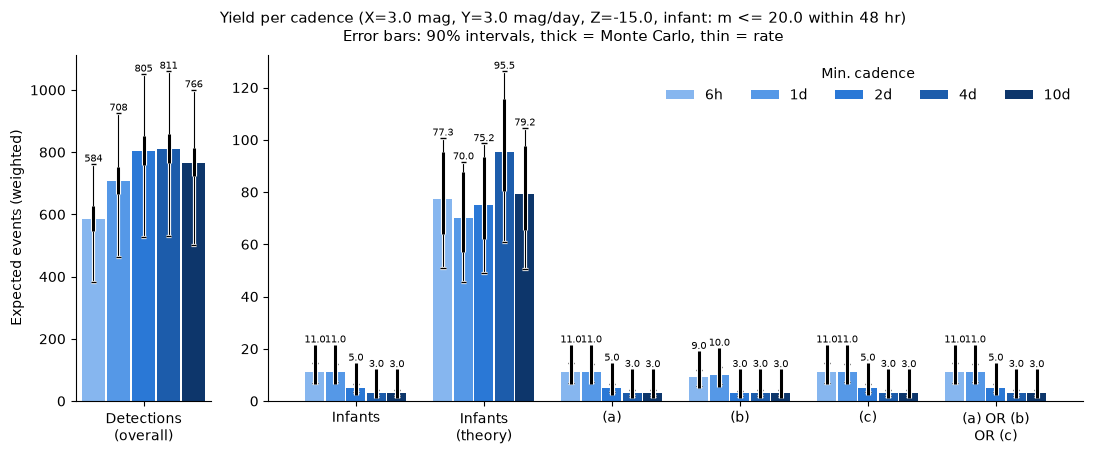

In [115]:
# =================================== #
# Yield comparison                    #
# =================================== #
# Expected number of events (sum of the event weights) in each category, for each cadence. The error bars
# come from the `uncertainty` table of the cell above: the thick bar is the MC interval and the thin bar with
# caps the rate interval. Both are 90% intervals, and the all-classes combination is approximate (see there).
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe


def weighted_count(schedule, event_ids):
    """Sum of the event weights over the given event ids."""
    summary = summary_tables[schedule]
    return float(np.sum(np.asarray(summary["weight"])[np.isin(summary["event_id"], event_ids)]))


categories = ["Detections\n(overall)", "Infants", "Infants\n(theory)", "(a)", "(b)", "(c)", "(a) OR (b)\nOR (c)"]

yields = {}
for schedule in SCHEDULES:
    if schedule not in summary_tables:
        continue
    summary = summary_tables[schedule]
    detected = np.asarray(summary["event_id"])[np.asarray(summary["n_det"]) > 0]
    yields[schedule] = [
        weighted_count(schedule, detected),
        weighted_count(schedule, infant_summary_tables[schedule]["event_id"]),
        weighted_count(schedule, infant_theory_event_ids[schedule]),
        weighted_count(schedule, cut_a_event_ids[schedule]),
        weighted_count(schedule, cut_b_event_ids[schedule]),
        weighted_count(schedule, cut_c_event_ids[schedule]),
        weighted_count(schedule, triggered_event_ids[schedule]),
    ]

# One blue ramp, light -> dark, for the ordered cadences 6h -> 10d.
colors = dict(zip(SCHEDULES, ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]))

# The overall detections dwarf everything else, so they get their own panel.
fig, (ax_det, ax_rest) = plt.subplots(
    1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 6], "wspace": 0.12}
)

n_sched = len(yields)
width = 0.8 / n_sched
for ax, cols, fmt in ((ax_det, [0], "%.0f"), (ax_rest, range(1, len(categories)), "%.1f")):
    x = np.arange(len(cols))
    for i, schedule in enumerate(yields):
        pos = x + (i - (n_sched - 1) / 2) * width
        values = np.array([yields[schedule][c] for c in cols])
        ax.bar(pos, values, width * 0.92, color=colors[schedule], label=schedule)

        # Error bars, with a white halo so they stay visible on the dark bars. `top` is where the label goes.
        totals = list(uncertainty[schedule].values())
        top = values.copy()
        for key, style in (("rate", dict(lw=0.8, capsize=2)), ("mc", dict(lw=2.2, capsize=0))):
            lower = np.clip(values - [totals[c][1][f"{key}_lower"] for c in cols], 0, None)
            upper = np.clip([totals[c][1][f"{key}_upper"] for c in cols] - values, 0, None)
            bars_err = ax.errorbar(pos, values, yerr=[lower, upper], fmt="none", ecolor="k", **style)
            for artist in (*bars_err[1], *bars_err[2]):
                artist.set_path_effects([pe.withStroke(linewidth=style["lw"] + 1.5, foreground="white")])
            top = np.maximum(top, values + upper)
        for p, v, t in zip(pos, values, top):
            ax.text(p, t, fmt % v, ha="center", va="bottom", fontsize=7)
    ax.set_xticks(x, [categories[c] for c in cols])
    ax.spines[["top", "right"]].set_visible(False)

ax_det.set_ylabel("Expected events (weighted)")
ax_rest.legend(title="Min. cadence", frameon=False, ncol=n_sched, loc="upper right")
fig.suptitle(f"Yield per cadence (X={X_BRIGHTEN} mag, Y={Y_RATE} mag/day, Z={Z_ABS_MAG}, "
             f"infant: m <= {INFANT_MAG} within {WINDOW_HR} hr)\n"
             f"Error bars: {confidence:.0%} intervals, thick = Monte Carlo, thin = rate", fontsize=11)
plt.show()


In [116]:
# =================================== #
# Infant population                   #
# =================================== #
# What kinds of events are the infant SNe? Raw counts, and the expected number (sum of weights).
for schedule in SCHEDULES:
    if schedule not in infant_summary_tables:
        continue

    infants = infant_summary_tables[schedule]
    types, inverse = np.unique(np.asarray(infants["transient_type"]), return_inverse=True)
    n_raw = np.bincount(inverse, minlength=len(types))
    n_weighted = np.bincount(inverse, weights=np.asarray(infants["weight"]), minlength=len(types))

    print(f"{schedule}: {len(infants)} infant SNe ({n_weighted.sum():.1f} expected)")
    for i in np.argsort(-n_weighted):
        print(f"    {types[i]:<16} {n_raw[i]:>3} events  ({n_weighted[i]:.1f} expected)")


6h: 11 infant SNe (11.0 expected)
    iip_sne            8 events  (8.0 expected)
    iib_sne            2 events  (2.0 expected)
    iip_excess_sne     1 events  (1.0 expected)
1d: 11 infant SNe (11.0 expected)
    iip_sne           10 events  (10.0 expected)
    iip_excess_sne     1 events  (1.0 expected)
2d: 5 infant SNe (5.0 expected)
    iip_sne            4 events  (4.0 expected)
    iip_excess_sne     1 events  (1.0 expected)
4d: 3 infant SNe (3.0 expected)
    iip_sne            2 events  (2.0 expected)
    iib_sne            1 events  (1.0 expected)
10d: 3 infant SNe (3.0 expected)
    iip_sne            2 events  (2.0 expected)
    iib_sne            1 events  (1.0 expected)


## Yield Uncertainties

The yield comparison above shows the all-classes intervals. Following the `uvex-transients` yield statistics, each class's yield is $\mu_0\,k/n$ with a Clopper-Pearson **MC** interval on $k/n$ and a separate **rate** interval from the class's rate normalization. Classes are not combined by the package, so the all-classes values are approximations (MC in quadrature, rate summed linearly); see the comments in the `uncertainty` cell above the plot. Below: the per-class breakdown of one selection.

In [117]:
# =================================== #
# Per-class yields and intervals      #
# =================================== #
# One selection, per class: selected / generated, the fraction with its Clopper-Pearson interval, and
# the expected yield with its MC and rate intervals (the `estimate_yield` columns).
SELECTION = "(a) OR (b) OR (c)"      # any key of `category_event_ids`

for schedule, by_category in uncertainty.items():
    table, totals = by_category[SELECTION]
    print(f"{schedule}: {SELECTION}  ({confidence:.0%} intervals)")
    print(f"    {'class':<16}{'k / n':>14}{'fraction (%)':>26}{'yield':>10}{'MC interval':>20}{'rate interval':>20}")
    for row in table:
        if row["n_selected"] == 0:
            result = f"{'< ' + format(row['expected_events_binom_upper'], '.1f'):>10}"
            mc = rate = ""
        else:
            result = f"{row['expected_events']:>10.1f}"
            mc = f"[{row['expected_events_binom_lower']:.1f}, {row['expected_events_binom_upper']:.1f}]"
            rate = f"[{row['expected_events_rate_lower']:.1f}, {row['expected_events_rate_upper']:.1f}]"
        frac = (f"{100 * row['fraction']:.3f} [{100 * row['fraction_lower']:.3f}, "
                f"{100 * row['fraction_upper']:.3f}]")
        print(f"    {row['transient_type']:<16}{row['n_selected']:>6} /{row['n_pre_cut']:>6}{frac:>26}"
              f"{result}{mc:>20}{rate:>20}")
    print()

6h: (a) OR (b) OR (c)  (90% intervals)
    class                    k / n              fraction (%)     yield         MC interval       rate interval
    ia_sne               0 /   201      0.000 [0.000, 1.479]     < 2.8                                        
    ib_sne               0 /    16     0.000 [0.000, 17.075]     < 2.1                                        
    ic_sne               0 /    64      0.000 [0.000, 4.573]     < 3.1                                        
    icbl_sne             0 /    13     0.000 [0.000, 20.582]     < 2.7                                        
    iib_sne              2 / 13692      0.015 [0.003, 0.046]       2.0          [0.4, 6.3]          [1.0, 2.9]
    iip_excess_sne       1 /  3265      0.031 [0.002, 0.145]       1.0          [0.1, 4.8]          [0.7, 1.3]
    iip_sne              8 /  6879      0.116 [0.058, 0.210]       8.0         [4.0, 14.5]         [5.3, 10.4]
    slsne                0 /    20     0.000 [0.000, 13.911]     < 2.5   

## Lightcurve Plots

---

In [118]:
print(infant_ids)

[ 1031 21280 28304]


In [143]:
# =================================== #
# Lightcurve settings                 #
# =================================== #
#[ 7479  8213  8248  8466  9914 15016 16936 18968 20480 23387 23759]
SCHEDULE = "6h"      # which cadence's tables to use
EVENT_ID = 23759    # the event to plot
CONFIG_DIR = "../configs"


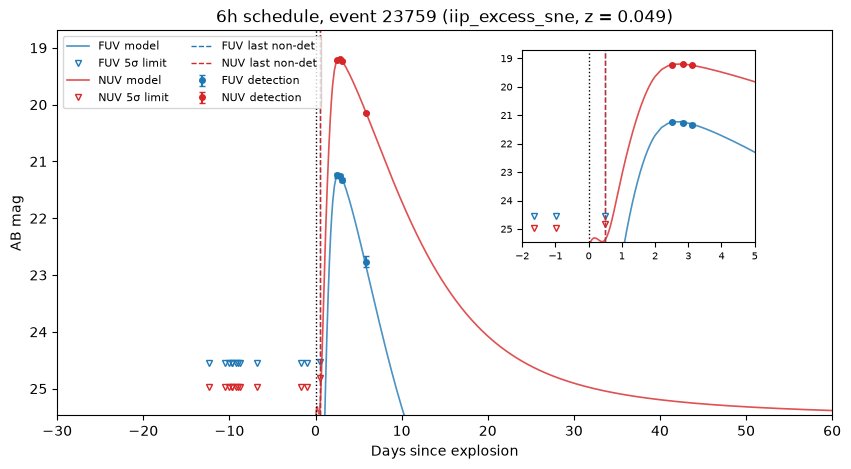

In [144]:
# =================================== #
# Single-event lightcurve             #
# =================================== #
# Measured photometry (detections and 5-sigma limits) against days since explosion, with the
# noiseless model ("theory") lightcurve of the same event. The model is rebuilt the way the
# simulation built it: the transient class from the run config, its SED parameters from the
# event's own `parameter_seed`, then the SED averaged over each UVEX bandpass, with the event's
# Milky Way reddening applied.
import astropy.units as u
import matplotlib.pyplot as plt
import yaml

import uvex_transients.transients
from uvex_transients.dust import log_attenuation
from uvex_transients.missions import get_mission
from uvex_transients.utils import get_rng

BAND_COLORS = {"FUV": "tab:blue", "NUV": "tab:red"}
X_RANGE = (-30, 60)       # days since explosion
INSET_RANGE = (-2, 5)

config = yaml.safe_load(open(Path(CONFIG_DIR) / f"infant_sne_{SCHEDULE}.yaml"))
bandpasses = get_mission(config["mission"]).detector.bandpasses


def theory_mag(event, band, t_days):
    """Noiseless apparent AB magnitude of the event's model in `band` at `t_days` since explosion."""
    transient = getattr(uvex_transients.transients, config["transients"][str(event["transient_type"])]["class"])()
    rng = get_rng(int(event["parameter_seed"]))
    sed_params = {name: value[0] for name, value in transient.sed.sample_parameters(size=1, rng=rng).items()}

    bandpass = bandpasses[band]
    nu = bandpass.waveset.to(u.Hz, equivalencies=u.spectral())
    mag = transient.sed.mag_bandpass(
        bandpass, t_days * u.day,
        redshift=float(event["redshift"]),
        luminosity_distance=float(event["luminosity_distance"]) * u.Mpc,
        log_attenuation=log_attenuation(nu, float(event["ebv"])),
        **sed_params,
    )
    return mag.value


summary = summary_tables[SCHEDULE]
event = summary[summary["event_id"] == EVENT_ID]
if len(event) == 0:
    raise ValueError(f"Event {EVENT_ID} is not in the {SCHEDULE} tables.")
event = event[0]

# Last non-detection of each band, in days since explosion (NaN if the event has none).
row = np.flatnonzero(summary["event_id"] == EVENT_ID)[0]
t_explosion_mjd = summary["t_explosion"].mjd[row]
t_last_nondet = {
    band: np.ma.filled(summary[f"t_last_nondet_{band}"].mjd, np.nan)[row] - t_explosion_mjd for band in BAND_COLORS
}

photometry = photometry_tables[SCHEDULE]
phot = photometry[photometry["event_id"] == EVENT_ID]
t = np.asarray(phot["rel_time"])
band_of = np.asarray(phot["band"])
detected = np.asarray(phot["snr"]) >= DET_SNR
ab_mag = np.asarray(phot["ab_mag"])
m_limit = -2.5 * np.log10(DET_SNR * np.asarray(phot["flux_err"]) / 3631)   # 5-sigma limit (flux in Jy)

# The model only exists after the explosion; sample the first couple of days more densely.
t_model = np.concatenate([np.linspace(0.005, 2, 300), np.linspace(2, X_RANGE[1], 300)[1:]])
theory = {band: theory_mag(event, band, t_model) for band in BAND_COLORS}


def draw(ax, labels):
    for band, color in BAND_COLORS.items():
        in_band = band_of == band
        det, non_det = in_band & detected, in_band & ~detected
        ax.plot(t_model, theory[band], color=color, lw=1.2, alpha=0.8, label=f"{band} model" if labels else None)
        ax.errorbar(t[det], ab_mag[det], yerr=phot["mag_err"][det], color=color, marker="o", ms=4, ls="",
                    capsize=2, label=f"{band} detection" if labels else None)
        ax.plot(t[non_det], m_limit[non_det], color=color, marker="v", mfc="none", ms=4, ls="",
                label=f"{band} 5σ limit" if labels else None)
    ax.axvline(0, color="k", ls=":", lw=1)
    for band, color in BAND_COLORS.items():
        if np.isfinite(t_last_nondet[band]):
            ax.axvline(t_last_nondet[band], color=color, ls="--", lw=1,
                       label=f"{band} last non-det" if labels else None)


def mag_range(window):
    """(faint, bright) magnitude limits for `window`: the faint end holds the detections and limits,
    the bright end also the model (which diverges to infinitely faint at the explosion)."""
    in_window = (t >= window[0]) & (t <= window[1])
    mags = np.concatenate([ab_mag[in_window & detected], m_limit[in_window & ~detected]])
    mags = mags[np.isfinite(mags)]
    in_model_window = (t_model >= window[0]) & (t_model <= window[1])
    model_bright = min(np.nanmin(theory[band][in_model_window]) for band in BAND_COLORS)
    return mags.max() + 0.5, min(mags.min(), model_bright) - 0.5


fig, ax = plt.subplots(figsize=(10, 5))
draw(ax, labels=True)
ax.set_xlim(*X_RANGE)
ax.set_ylim(*mag_range(X_RANGE))
ax.set_xlabel("Days since explosion")
ax.set_ylabel("AB mag")
ax.set_title(f"{SCHEDULE} schedule, event {EVENT_ID} ({event['transient_type']}, z = {event['redshift']:.3f})")
ax.legend(fontsize=8, ncol=2, loc="upper left")

inset = ax.inset_axes([0.6, 0.45, 0.3, 0.5])
draw(inset, labels=False)
inset.set_xlim(*INSET_RANGE)
inset.set_ylim(*mag_range(INSET_RANGE))
inset.tick_params(labelsize=7)
plt.show()
